In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git opencv-python
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
!unzip -q all_images.zip -d .
!ls all_images | head -3

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
not_damaged_100_jpg.rf.5d780a6024004fa2f68741fa56ddf4c9.jpg
not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
not_damaged_102_jpg.rf.8d754cbc174c6cb6fb1b5c1929edcbb1.jpg


In [2]:
import os, glob, cv2, numpy as np, torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

sam = sam_model_registry["vit_h"](checkpoint="sam_vit_h_4b8939.pth").cuda()
gen = SamAutomaticMaskGenerator(sam, points_per_side=32, pred_iou_thresh=0.86,
                                stability_score_thresh=0.9, min_mask_region_area=200)

def egg_masks(img):
    H, W = img.shape[:2]
    cands = []
    for m in gen.generate(img):
        frac = m["area"] / (H * W)
        if not 0.003 < frac < 0.4:           # too tiny or too big (hand/floor)
            continue
        seg = m["segmentation"].astype(np.uint8)
        cnts, _ = cv2.findContours(seg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cnts, key=cv2.contourArea)
        if len(c) < 5:
            continue
        area = cv2.contourArea(c)
        solidity = area / cv2.contourArea(cv2.convexHull(c))   # eggs are convex
        (_, _), (a, b), _ = cv2.fitEllipse(c)
        ell = area / (np.pi * a * b / 4)                       # eggs ≈ ellipses
        if solidity < 0.93 or not 0.8 < ell < 1.2:
            continue
        cands.append((solidity * m["predicted_iou"], seg))
    cands.sort(key=lambda x: -x[0])
    keep = []                                # drop overlapping duplicates
    for s, seg in cands:
        if all((seg & k).sum() / min(seg.sum(), k.sum()) < 0.5 for k in keep):
            keep.append(seg)
    return keep

In [6]:
import pickle
raw = {}
for p in sorted(glob.glob("all_images/*")):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    items = []
    for m in gen.generate(img):
        frac = m["area"] / (H * W)
        if frac < 0.003:
            continue
        seg = m["segmentation"].astype(np.uint8)
        cnts, _ = cv2.findContours(seg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cnts, key=cv2.contourArea)
        if len(c) < 5:
            continue
        area = cv2.contourArea(c)
        sol = area / cv2.contourArea(cv2.convexHull(c))
        (_, _), (a, b), _ = cv2.fitEllipse(c)
        x, y, w, h = cv2.boundingRect(c)
        border = x <= 1 or y <= 1 or x + w >= W - 1 or y + h >= H - 1
        items.append(dict(seg=np.packbits(seg), shape=seg.shape, frac=frac, sol=sol,
                          ell=area / (np.pi * a * b / 4), iou=m["predicted_iou"], border=border))
    raw[p] = items
pickle.dump(raw, open("raw_masks.pkl", "wb"))
print("done", len(raw))

done 108


In [10]:
def select(items, min_frac=0.015, rel=0.25, sol=0.95, ell_lo=0.88, ell_hi=1.12,
           max_eggs=5, allow_border=False):
    c = [i for i in items if i["frac"] >= min_frac and i["sol"] >= sol
         and ell_lo < i["ell"] < ell_hi and (allow_border or not i["border"])]
    c.sort(key=lambda i: -(i["sol"] * i["iou"]))
    keep = []
    for i in c:
        seg = np.unpackbits(i["seg"])[:i["shape"][0] * i["shape"][1]].reshape(i["shape"])
        if all((seg & k).sum() / min(seg.sum(), k.sum()) < 0.5 for k in keep):
            keep.append(seg)
    if keep:
        biggest = max(k.sum() for k in keep)
        keep = [k for k in keep if k.sum() >= rel * biggest]
    return keep[:max_eggs]

os.makedirs("sam_masks", exist_ok=True); os.makedirs("sam_overlays", exist_ok=True)
counts = {}
for p, items in raw.items():
    bgr = cv2.imread(p); masks = select(items)
    label = np.zeros(bgr.shape[:2], np.uint8)
    for n, seg in enumerate(masks, 1):
        label[seg > 0] = n
    name = os.path.splitext(os.path.basename(p))[0]
    cv2.imwrite(f"sam_masks/{name}.png", label)
    ov = bgr.copy()
    ov[label > 0] = (0.5 * ov[label > 0] + 0.5 * np.array([0, 0, 255])).astype(np.uint8)
    cv2.imwrite(f"sam_overlays/{name}.jpg", ov)
    counts[name] = len(masks)
print("0 eggs:", [k for k, v in counts.items() if v == 0])
print("distribution:", np.bincount(list(counts.values())))

0 eggs: ['not_damaged_11_jpg.rf.95e1bc4944748cfd1a56fe23a42b6ae8', 'not_damaged_12_jpg.rf.339e366cebec5c32e751e8500aa12f3e', 'not_damaged_13_jpg.rf.60964651b01aed5680a994ecbd7012ea', 'not_damaged_44_jpg.rf.a4dbaabec5b64e4c34d874a6870964be']
distribution: [ 4 80 14 10]


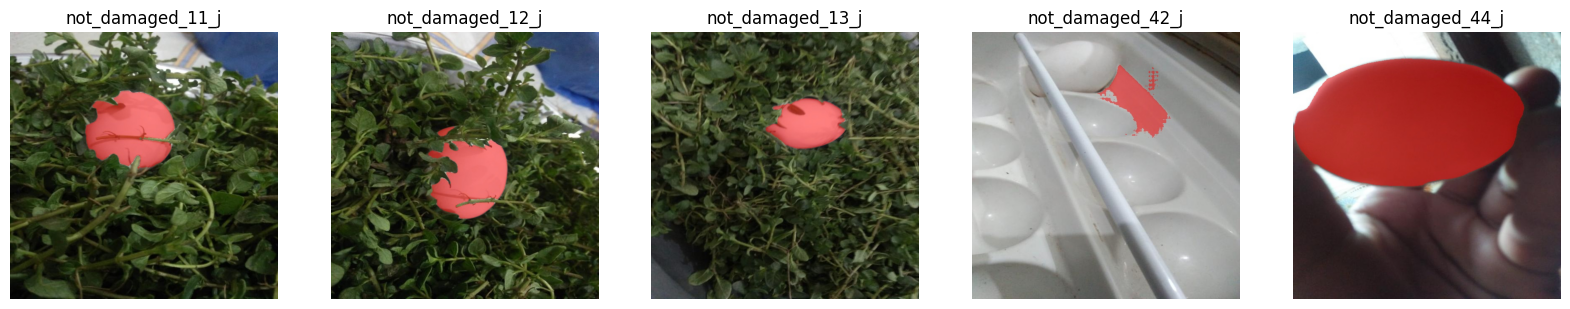

In [13]:
from segment_anything import SamPredictor
pred = SamPredictor(sam)

# [x0, y0, x1, y1] as fractions of width/height; tweak if the overlay is off
box_fixes = {"not_damaged_12_": [0.35, 0.35, 0.70, 0.70],
             "not_damaged_42_": [0.45, 0.08, 0.75, 0.40]}
relaxed = {"not_damaged_11_", "not_damaged_13_", "not_damaged_44_"}

def save(p, label):
    bgr = cv2.imread(p)
    name = os.path.splitext(os.path.basename(p))[0]
    cv2.imwrite(f"sam_masks/{name}.png", label)
    ov = bgr.copy()
    ov[label > 0] = (0.5 * ov[label > 0] + 0.5 * np.array([0, 0, 255])).astype(np.uint8)
    cv2.imwrite(f"sam_overlays/{name}.jpg", ov)
    return name

fixed = []
for p in raw:
    b = os.path.basename(p)
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    pre = next((k for k in box_fixes if b.startswith(k)), None)
    if pre:
        pred.set_image(img)
        x0, y0, x1, y1 = box_fixes[pre]
        m, _, _ = pred.predict(box=np.array([x0*W, y0*H, x1*W, y1*H]), multimask_output=False)
        fixed.append(save(p, m[0].astype(np.uint8)))
    elif any(b.startswith(k) for k in relaxed):
        masks = select(raw[p], sol=0.88, ell_lo=0.8, ell_hi=1.2, allow_border=True)
        label = np.zeros((H, W), np.uint8)
        for n, seg in enumerate(masks, 1):
            label[seg > 0] = n
        fixed.append(save(p, label))

fig, ax = plt.subplots(1, len(fixed), figsize=(4 * len(fixed), 4))
for a, n in zip(ax, fixed):
    a.imshow(cv2.cvtColor(cv2.imread(f"sam_overlays/{n}.jpg"), cv2.COLOR_BGR2RGB))
    a.axis("off"); a.set_title(n[:16])
plt.show()

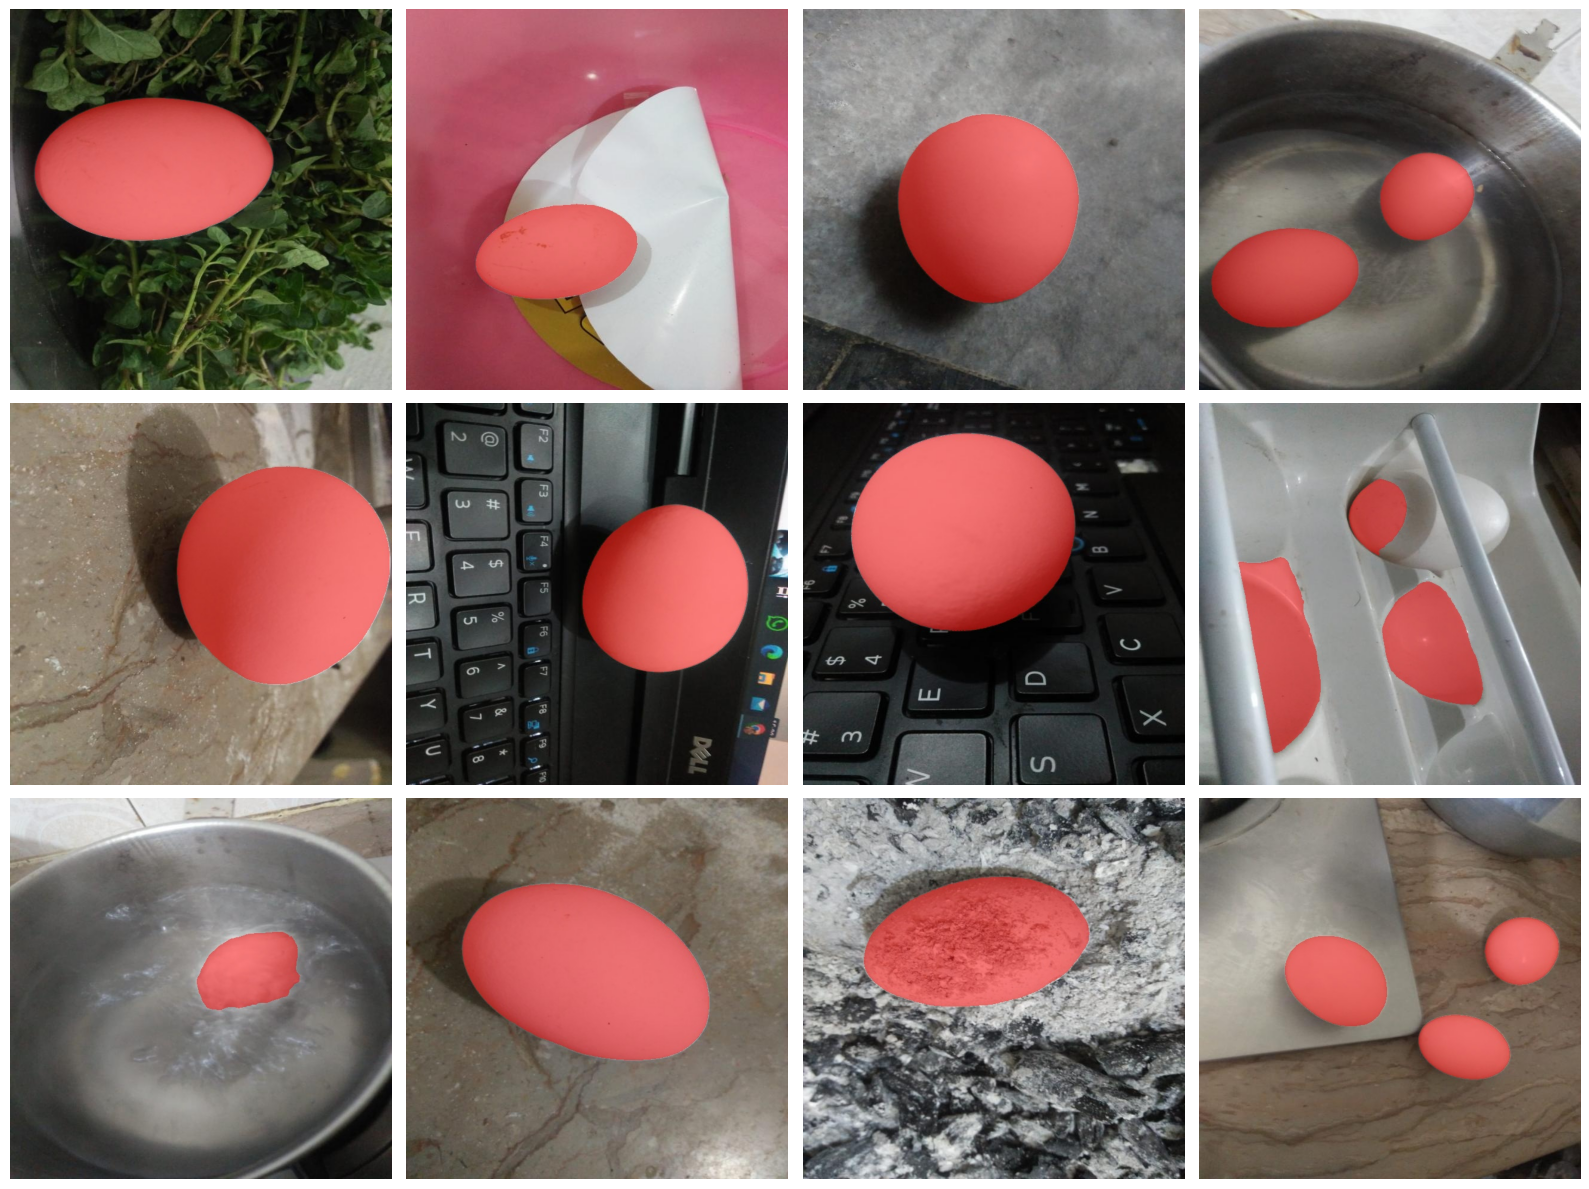

In [8]:
import matplotlib.pyplot as plt, random
files = random.sample(sorted(glob.glob("sam_overlays/*")), 12)
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for a, f in zip(ax.ravel(), files):
    a.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)); a.axis("off")
plt.tight_layout(); plt.show()

In [5]:
!zip -qr sam_results.zip sam_masks sam_overlays
from google.colab import files; files.download("sam_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

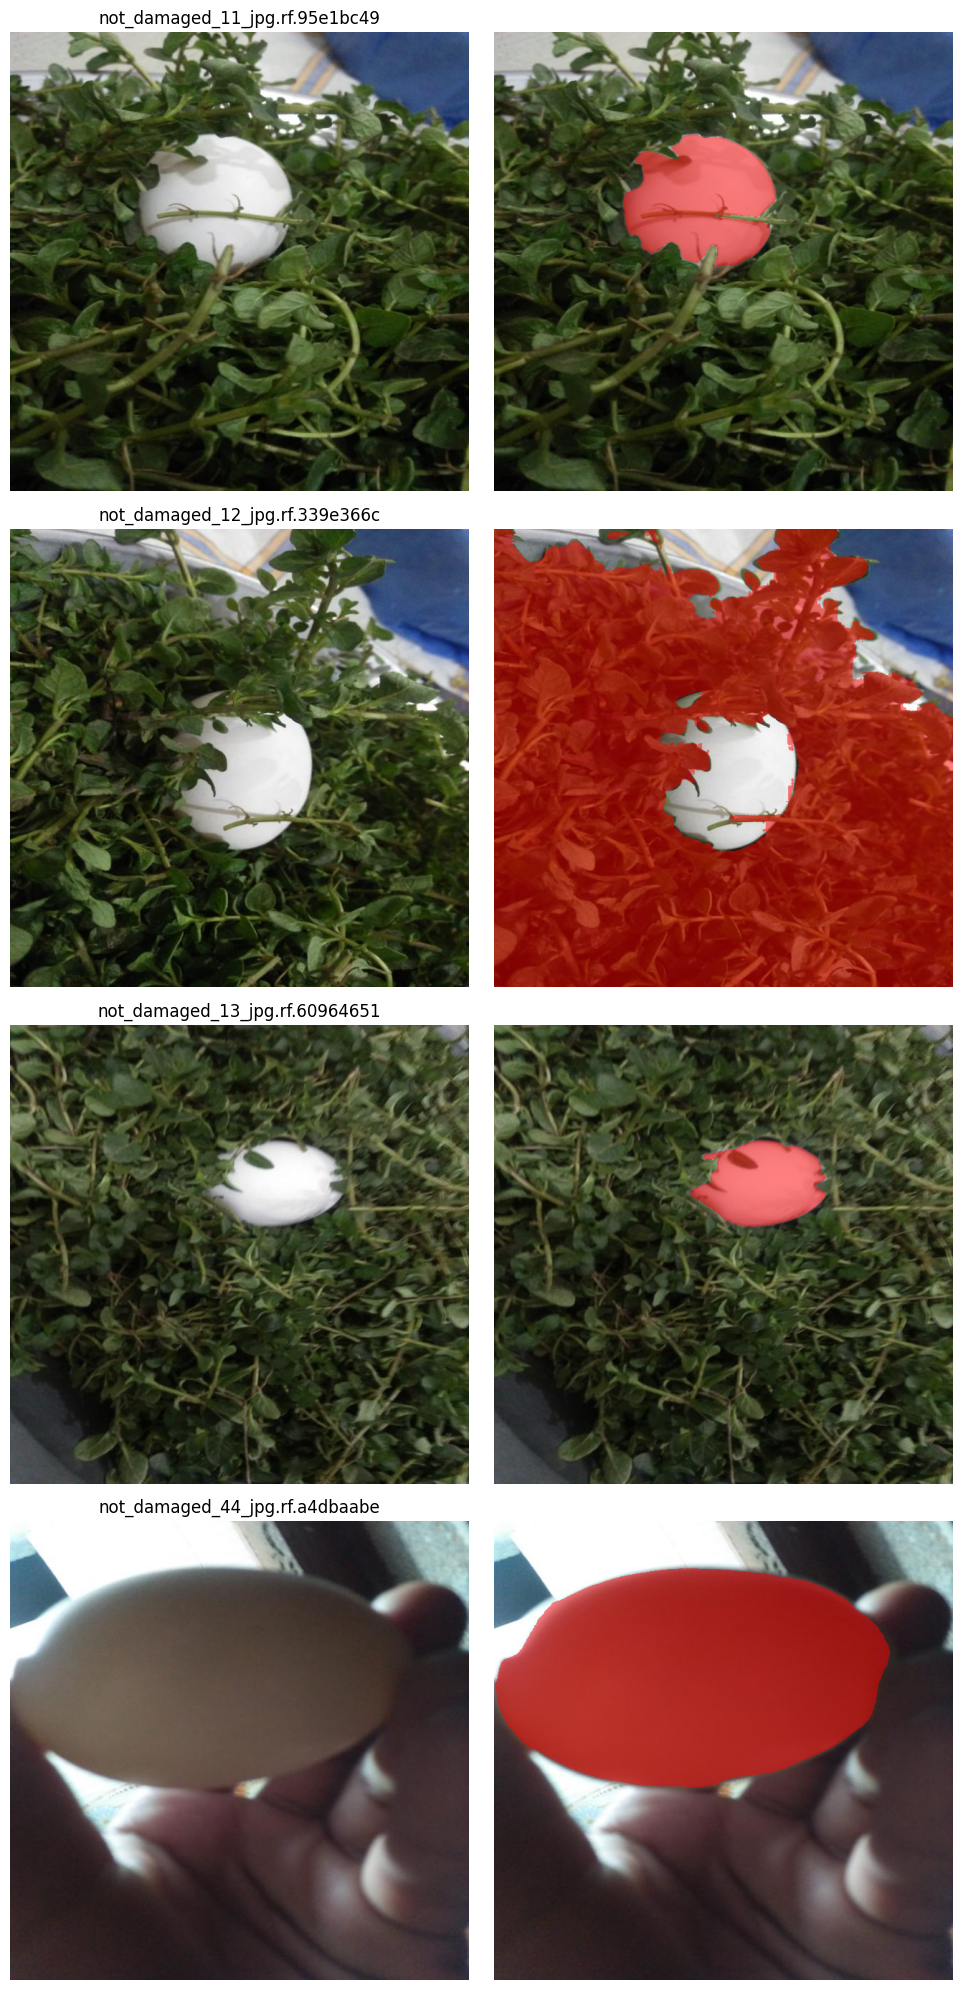

In [11]:
zero = [p for p, it in raw.items() if len(select(it)) == 0]
fig, ax = plt.subplots(len(zero), 2, figsize=(10, 5 * len(zero)))
for r, p in enumerate(zero):
    bgr = cv2.imread(p)
    masks = select(raw[p], sol=0.88, ell_lo=0.8, ell_hi=1.2, allow_border=True)
    ov = bgr.copy()
    for seg in masks:
        ov[seg > 0] = (0.5 * ov[seg > 0] + 0.5 * np.array([0, 0, 255])).astype(np.uint8)
    ax[r, 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[r, 0].axis("off")
    ax[r, 1].imshow(cv2.cvtColor(ov, cv2.COLOR_BGR2RGB)); ax[r, 1].axis("off")
    ax[r, 0].set_title(os.path.basename(p)[:30])
plt.tight_layout(); plt.show()

In [12]:
import re, collections
def base(p):
    n = os.path.splitext(os.path.basename(p))[0]
    n = re.sub(r"^(train|valid|test)_", "", n)
    return re.sub(r"_jpg\.rf\..*$", "", n)
groups = collections.Counter(base(p) for p in raw)
print(len(groups), "unique source images out of", len(raw))
print([g for g, c in groups.items() if c > 1][:10])

108 unique source images out of 108
[]


In [14]:
import glob
for f in glob.glob("sam_masks/not_damaged_42_*") + glob.glob("sam_overlays/not_damaged_42_*"):
    os.remove(f)

with open("excluded_images.txt", "w") as f:
    f.write("not_damaged_42: SAM failed (white eggs in white tray, no usable mask); excluded from GT\n")

print(len(os.listdir("sam_masks")), "masks")   # should print 107
!zip -qr sam_results.zip sam_masks sam_overlays excluded_images.txt raw_masks.pkl
from google.colab import files; files.download("sam_results.zip")

107 masks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>